# IFRS 9 — laboratorio ejecutable

**Datos sintéticos; no es una estimación contable ni un modelo productivo.**

## tl;dr
Este notebook calcula ECL multiescenario, staging y una tabla de calibración reproducible.

## Contexto y ecuaciones

La pérdida esperada por horizonte es:

$$ECL = \sum_{t=1}^{T} PD_t^{marginal} \times LGD_t \times EAD_t \times DF_t$$

Stage 1 usa 12 meses; Stages 2 y 3 usan horizonte de vida. Los escenarios se ponderan: $ECL^w=\sum_s w_sECL_s$.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.ifrs9_engine import cartera_sintetica, ecl_componentes, ponderar_escenarios, backtest_pd
import numpy as np
import matplotlib.pyplot as plt
cartera = cartera_sintetica(2_000, 91)
pesos = {'base': .60, 'adverso': .30, 'severo': .10}

In [2]:
escenarios = {s: ecl_componentes(cartera, s) for s in pesos}
resumen = {s: df.ecl.sum() for s, df in escenarios.items()}
ponderado = ponderar_escenarios(cartera, pesos)
resumen, ponderado.ecl_ponderada.sum()

({'base': np.float64(4842633.233718576),
  'adverso': np.float64(8028680.342486562),
  'severo': np.float64(12752162.697426377)},
 np.float64(6589400.312719751))

## Resultados
La severidad del escenario aumenta PD y LGD por construcción; esto es una prueba de sensibilidad, no una proyección macroeconómica.

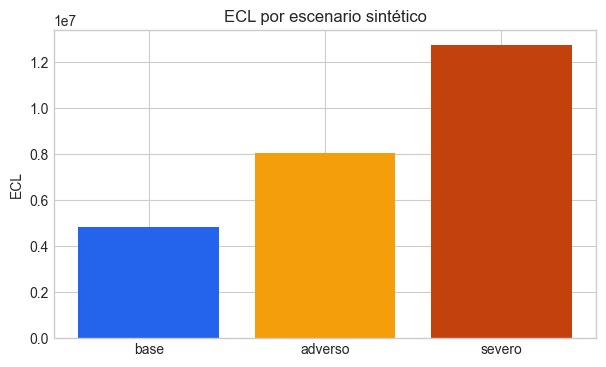

In [3]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(resumen.keys(), resumen.values(), color=['#2463eb','#f59e0b','#c2410c'])
ax.set(title='ECL por escenario sintético', ylabel='ECL')
plt.show()

In [4]:
base = escenarios['base']
base.groupby('stage').agg(cuentas=('loan_id','size'), ecl=('ecl','sum'), exposicion=('ead','sum')).round(2)

,cuentas,ecl,exposicion
stage,,,
1,1813,3526661.29,99767915.27
2,130,851250.90,6874111.81
3,57,464721.04,3498881.40


## Backtesting de PD
Se simulan defaults OOT coherentes con la PD para ilustrar la tabla de calibración. En uso real se reemplaza por una muestra OOT gobernada.

In [5]:
rng = np.random.default_rng(12)
default_oot = rng.binomial(1, cartera.pd_12m)
calibracion = backtest_pd(cartera.pd_12m, default_oot)
calibracion

,cuentas,pd_media,default_observado,error_calibracion
banda,,,,
0,200,0.011310,0.020,0.008690
1,200,0.021324,0.020,-0.001324
2,200,0.030299,0.050,0.019701
3,200,0.038947,0.060,0.021053
4,200,0.049114,0.030,-0.019114
5,200,0.062875,0.075,0.012125
6,200,0.080832,0.070,-0.010832
7,200,0.103637,0.115,0.011363
8,200,0.140277,0.150,0.009723


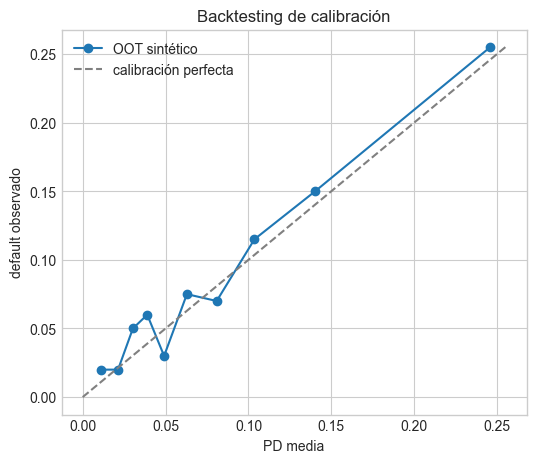

In [6]:
fig, ax = plt.subplots(figsize=(6,5))
ax.plot(calibracion.pd_media, calibracion.default_observado, 'o-', label='OOT sintético')
ax.plot([0, max(calibracion.pd_media.max(), calibracion.default_observado.max())], [0, max(calibracion.pd_media.max(), calibracion.default_observado.max())], '--', color='gray', label='calibración perfecta')
ax.set(xlabel='PD media', ylabel='default observado', title='Backtesting de calibración')
ax.legend(); plt.show()

## Límites
No incorpora definición regulatoria de default, datos observados, overlays de gestión, recuperación histórica, ni aprobación contable. Antes de uso productivo se requiere validación independiente, gobierno de modelos y fuentes trazables.